# 08 · Los modelos y sus funciones
**Objetivo:** mostrar **qué modelo exacto** se usó en cada análisis y **la función (ecuación o reglas)** que generó cada uno.

| Análisis | Modelos probados | **Modelo final** | Tipo de "función" que genera |
|---|---|---|---|
| **Regresión** (predecir `Rings`) | Regresión lineal, Árbol de decisión, Random Forest | **Random Forest Regressor** | Lineal: ecuación *y = b₀ + b₁x₁ + …* · Árbol: reglas SI–ENTONCES · Random Forest: promedio de 200 árboles |
| **Clasificación** (Joven / Adulto / Maduro) | Regresión logística, KNN, Random Forest | **Random Forest Classifier** | Logística: una ecuación por clase · Random Forest: votación de 200 árboles |
| **No supervisado** | K-Means (k = 3) + PCA | **K-Means + PCA** | K-Means: 3 centros · PCA: combinación lineal de las medidas |

🧠 **Supervisado vs. no supervisado**
- **Supervisado** (regresión y clasificación): el modelo se **entrena** con el **80%** de los datos **con su respuesta** (los anillos o el grupo). Después se **prueba** con el otro **20%**, dándole **solo las medidas**; el modelo predice y se **compara** con la respuesta real.
- **No supervisado** (K-Means): **no se le da la respuesta**; el modelo encuentra solo los patrones (grupos) en los datos.

Para que las ecuaciones se entiendan, aquí se usan las medidas en **unidades reales (mm y g)**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

pd.set_option("display.float_format", "{:.4f}".format)
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_MOD = Path("..") / "modelos"
df = pd.read_csv(Path("..") / "data" / "processed" / "abalone_limpio.csv")

MEDIDAS = ["Length_mm", "Diameter_mm", "Height_mm", "Whole_weight_g",
           "Shucked_weight_g", "Viscera_weight_g", "Shell_weight_g"]
# Sex se convierte en 2 columnas 0/1 (Sex_I, Sex_M); "Hembra" queda como referencia
X = pd.get_dummies(df[MEDIDAS + ["Sex"]], columns=["Sex"], drop_first=True, dtype=float)

# Misma división 80% entrenamiento / 20% prueba de los notebooks 04 y 05
train, test = train_test_split(df.index, test_size=0.2, random_state=42)
X_tr, X_te = X.loc[train], X.loc[test]
y_tr, y_te = df.loc[train, "Rings"], df.loc[test, "Rings"]
print("Entrenamiento:", len(train), "| Prueba:", len(test))

Entrenamiento: 3335 | Prueba: 834


---
## 1. Regresión lineal SIMPLE: la recta *y = mx + b*
Primero con **una sola variable**, la más relacionada con la edad: el **peso de la concha**.
- **y** = número de anillos (Rings)
- **x** = peso de la concha en gramos
- **m** = pendiente: cuántos anillos aumenta por cada gramo
- **b** = ordenada al origen: valor de *y* cuando *x* = 0

In [2]:
simple = LinearRegression().fit(X_tr[["Shell_weight_g"]], y_tr)
m, b = simple.coef_[0], simple.intercept_
print(f"ECUACIÓN:  Rings = {m:.4f} × Peso_concha_g + {b:.4f}")
print(f"           Edad (años) = Rings + 1.5")
pred = simple.predict(X_te[["Shell_weight_g"]])
print(f"\nEn prueba -> MAE: {mean_absolute_error(y_te, pred):.3f} anillos | R²: {r2_score(y_te, pred):.3f}")

ejemplo = 50
print(f"\nEjemplo: un abulón con concha de {ejemplo} g -> Rings = {m:.4f}×{ejemplo} + {b:.4f} = {m*ejemplo+b:.2f} anillos "
      f"(≈ {m*ejemplo+b+1.5:.1f} años)")

ECUACIÓN:  Rings = 0.0705 × Peso_concha_g + 6.5341
           Edad (años) = Rings + 1.5

En prueba -> MAE: 1.846 anillos | R²: 0.446

Ejemplo: un abulón con concha de 50 g -> Rings = 0.0705×50 + 6.5341 = 10.06 anillos (≈ 11.6 años)


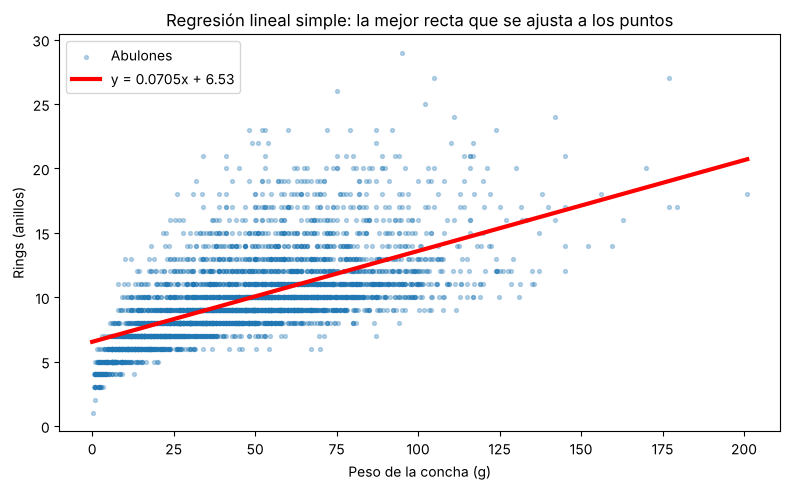

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["Shell_weight_g"], df["Rings"], s=8, alpha=0.3, label="Abulones")
xs = np.linspace(0, df["Shell_weight_g"].max(), 100)
ax.plot(xs, m * xs + b, color="red", linewidth=3, label=f"y = {m:.4f}x + {b:.2f}")
ax.set_xlabel("Peso de la concha (g)"); ax.set_ylabel("Rings (anillos)")
ax.set_title("Regresión lineal simple: la mejor recta que se ajusta a los puntos")
ax.legend()
plt.tight_layout(); plt.savefig(RUTA_FIG / "26_regresion_lineal_simple.png", dpi=130); plt.show()

**Interpretación:** la pendiente **m ≈ 0.07** significa que **por cada gramo más de concha, el abulón tiene 0.07 anillos más**; o sea, cada **14 g** de concha equivale aproximadamente a **1 anillo (1 año)**. La ordenada **b ≈ 6.5** es el valor teórico para una concha de 0 g.

Con una sola variable el error es de **≈ 1.85 anillos** y R² ≈ 0.45: la recta capta la tendencia, pero la nube es muy ancha.

---
## 2. Regresión lineal MÚLTIPLE: *y = b₀ + b₁x₁ + b₂x₂ + … + bₙxₙ*
Es la misma idea, pero con **todas** las medidas y el sexo. En lugar de una recta es un **hiperplano**: una "recta" en muchas dimensiones.

In [4]:
multiple = LinearRegression().fit(X_tr, y_tr)
coef = pd.Series(multiple.coef_, index=X.columns)
terminos = " ".join(f"{'+' if v >= 0 else '-'} {abs(v):.4f}·{n}" for n, v in coef.items())
print("ECUACIÓN:\nRings =", f"{multiple.intercept_:.4f}", terminos)
pred = multiple.predict(X_te)
print(f"\nEn prueba -> MAE: {mean_absolute_error(y_te, pred):.3f} anillos | R²: {r2_score(y_te, pred):.3f}")
coef.to_frame("Coeficiente")

ECUACIÓN:
Rings = 3.5611 - 0.0233·Length_mm + 0.0649·Diameter_mm + 0.1290·Height_mm + 0.0444·Whole_weight_g - 0.0964·Shucked_weight_g - 0.0508·Viscera_weight_g + 0.0317·Shell_weight_g - 0.7031·Sex_I + 0.0589·Sex_M

En prueba -> MAE: 1.517 anillos | R²: 0.616


,Coeficiente
Length_mm,-0.0233
Diameter_mm,0.0649
Height_mm,0.1290
Whole_weight_g,0.0444
Shucked_weight_g,-0.0964
Viscera_weight_g,-0.0508
Shell_weight_g,0.0317
Sex_I,-0.7031
Sex_M,0.0589


**Interpretación:**
- **Sex_I ≈ −0.70:** si es **infante**, el modelo le resta **0.7 anillos** respecto a una hembra de las mismas medidas.
- **Height_mm ≈ +0.13:** cada mm de altura suma 0.13 anillos.
- Algunos coeficientes son **negativos** (por ejemplo, el peso de la carne). No significa que más carne = más joven: las medidas están **muy correlacionadas** entre sí (> 0.9), y el modelo "reparte" el efecto entre ellas (**multicolinealidad**). Por eso el peso de cada variable por separado no se interpreta solo.
- Con todas las variables el error baja a **≈ 1.52 anillos** (contra 1.85 con una sola).

---
## 3. Modelo FINAL de regresión: Random Forest Regressor
**Random Forest no produce una sola ecuación.** Es un "bosque" de **200 árboles de decisión**; cada árbol aprende reglas SI–ENTONCES con una muestra distinta de los datos, y la predicción final es el **promedio** de los 200 árboles:

$$\hat{y} = \frac{1}{200}\sum_{i=1}^{200} \text{árbol}_i(x)$$

Su "función" se describe con la **importancia de cada variable**: cuánto ayuda cada medida a reducir el error.

In [5]:
rf_reg = joblib.load(RUTA_MOD / "regresion_random_forest.joblib")
modelo = rf_reg.named_steps["modelo"]
print("Parámetros del modelo final:", {k: modelo.get_params()[k] for k in ["n_estimators", "min_samples_leaf", "max_features"]})
print("Número de árboles:", len(modelo.estimators_))
imp = pd.Series(modelo.feature_importances_,
                index=[n.split("__")[1] for n in rf_reg.named_steps["prep"].get_feature_names_out()])
(imp.sort_values(ascending=False) * 100).round(1).to_frame("Importancia (%)")

Parámetros del modelo final: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.5}
Número de árboles: 200


,Importancia (%)
Shell_weight,42.1000
Height,15.7000
Shucked_weight,13.2000
Whole_weight,10.0000
Viscera_weight,7.2000
Diameter,5.5000
Length,3.6000
Sex_I,1.7000
Sex_M,0.5000
Sex_F,0.5000


**Interpretación:** el **peso de la concha** es por mucho la variable que más usa el bosque. Random Forest gana a la regresión lineal (MAE ≈ 1.49 contra 1.52) porque sus árboles captan relaciones **no lineales**, por ejemplo que los adultos casi dejan de crecer.

---
## 4. Clasificación: las REGLAS de un árbol de decisión
Para ver cómo "piensa" cada árbol del bosque, se entrena **un solo árbol pequeño** (3 niveles) que clasifica el **grupo de edad**. Su función son **reglas SI–ENTONCES**:

In [6]:
# Misma división ESTRATIFICADA del notebook 05 (clasificación)
train_c, test_c = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df["Grupo_Edad"])
X_tr_c, X_te_c = X.loc[train_c], X.loc[test_c]
g_tr, g_te = df.loc[train_c, "Grupo_Edad"], df.loc[test_c, "Grupo_Edad"]
arbol = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr_c, g_tr)
print(export_text(arbol, feature_names=list(X.columns)))
print(f"Exactitud de este árbol pequeño en prueba: {accuracy_score(g_te, arbol.predict(X_te_c)):.3f}")

|--- Shell_weight_g <= 35.55
|   |--- Sex_I <= 0.50
|   |   |--- Viscera_weight_g <= 5.80
|   |   |   |--- class: Joven
|   |   |--- Viscera_weight_g >  5.80
|   |   |   |--- class: Joven
|   |--- Sex_I >  0.50
|   |   |--- Shell_weight_g <= 23.95
|   |   |   |--- class: Joven
|   |   |--- Shell_weight_g >  23.95
|   |   |   |--- class: Joven
|--- Shell_weight_g >  35.55
|   |--- Shell_weight_g <= 70.85
|   |   |--- Shucked_weight_g <= 64.95
|   |   |   |--- class: Maduro
|   |   |--- Shucked_weight_g >  64.95
|   |   |   |--- class: Adulto
|   |--- Shell_weight_g >  70.85
|   |   |--- Shell_weight_g <= 87.55
|   |   |   |--- class: Maduro
|   |   |--- Shell_weight_g >  87.55
|   |   |   |--- class: Maduro

Exactitud de este árbol pequeño en prueba: 0.583


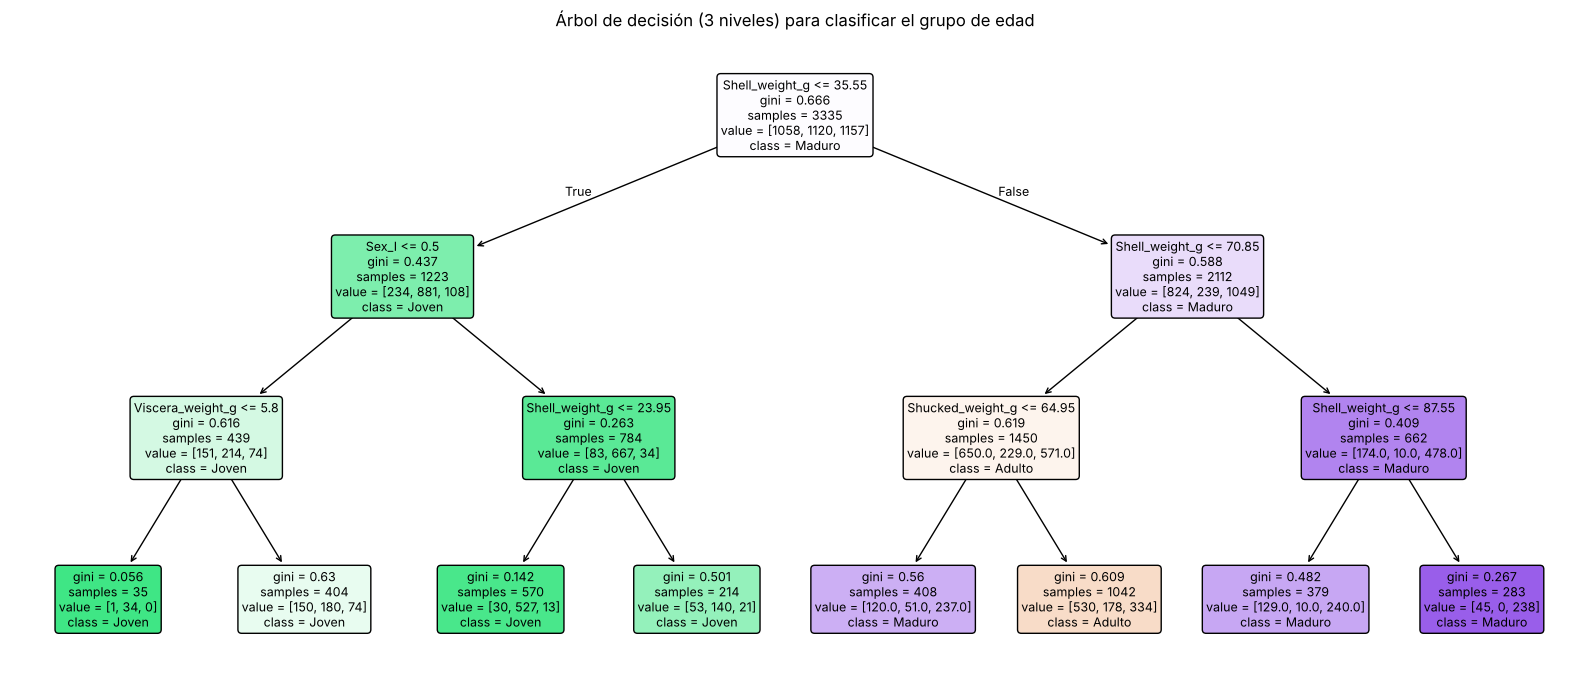

In [7]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(arbol, feature_names=list(X.columns), class_names=list(arbol.classes_),
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Árbol de decisión (3 niveles) para clasificar el grupo de edad")
plt.tight_layout(); plt.savefig(RUTA_FIG / "27_arbol_decision.png", dpi=110); plt.show()

**Cómo se lee:** la primera pregunta es **¿el peso de la concha es ≤ 35.6 g?**
- **Sí** → casi siempre es **Joven**.
- **No** → si la concha pesa **más de 70.9 g**, es **Maduro**; entre 35.6 y 70.9 g decide con el **peso de la carne**: mucha carne → **Adulto**, poca carne → **Maduro**.

El **Random Forest Classifier final** hace esto con **200 árboles más profundos** y cada uno **vota** por un grupo; gana el más votado. Así sube de ≈ 58% (un solo árbol pequeño) a ≈ **64%** de exactitud.

---
## 5. Clasificación: regresión logística (una ecuación por clase)
La regresión logística calcula una **puntuación lineal** para cada grupo y la convierte en **probabilidad** con la función *softmax*:

$$z_{clase} = b_0 + b_1x_1 + \dots + b_nx_n \qquad P(clase) = \frac{e^{z_{clase}}}{\sum e^{z}}$$

Se gana la clase con mayor probabilidad. Las variables se estandarizan, así que cada coeficiente indica el efecto de **subir 1 desviación estándar** esa medida.

In [8]:
esc = StandardScaler().fit(X_tr_c)
log = LogisticRegression(max_iter=2000).fit(esc.transform(X_tr_c), g_tr)
coef_log = pd.DataFrame(log.coef_.T, index=X.columns, columns=log.classes_)
coef_log.loc["(Intercepto b0)"] = log.intercept_
print(f"Exactitud en prueba: {accuracy_score(g_te, log.predict(esc.transform(X_te_c))):.3f}")
coef_log[["Joven", "Adulto", "Maduro"]]

Exactitud en prueba: 0.635


,Joven,Adulto,Maduro
Length_mm,0.2457,0.3405,-0.5862
Diameter_mm,-0.3881,0.1193,0.2688
Height_mm,-0.4059,0.0476,0.3583
Whole_weight_g,-1.1184,-1.1132,2.2316
Shucked_weight_g,1.8182,0.4086,-2.2269
Viscera_weight_g,-0.0261,0.2980,-0.2719
Shell_weight_g,-1.6247,0.3495,1.2752
Sex_I,0.3062,-0.1383,-0.1679
Sex_M,0.0174,-0.0046,-0.0127
(Intercepto b0),-0.4794,0.3257,0.1537


**Interpretación:** en la columna **Maduro**, el coeficiente del **peso de la concha** es positivo y en **Joven** es negativo: una concha más pesada **aumenta** la probabilidad de ser maduro y **reduce** la de ser joven.

---
## 6. No supervisado: la función de K-Means son sus 3 CENTROS
K-Means guarda **3 centros** (un abulón "típico" de cada perfil). Para clasificar un abulón nuevo, calcula la **distancia** a cada centro y lo asigna al **más cercano**:

$$\text{perfil}(x) = \arg\min_{k} \; \lVert x - \mu_k \rVert$$

In [9]:
nos = joblib.load(RUTA_MOD / "kmeans_pca.joblib")
medidas_esc = ["Length", "Diameter", "Height", "Whole_weight", "Shucked_weight", "Viscera_weight", "Shell_weight"]
centros = pd.DataFrame(nos["escalador"].inverse_transform(nos["kmeans"].cluster_centers_) * 200,
                       columns=[c + (" (mm)" if c in ["Length", "Diameter", "Height"] else " (g)") for c in medidas_esc])
centros.index = [nos["nombres"][i] for i in range(len(centros))]
centros.loc[["Pequeño", "Mediano", "Grande"]].round(1)

,Length (mm),Diameter (mm),Height (mm),Whole_weight (g),Shucked_weight (g),Viscera_weight (g),Shell_weight (g)
Pequeño,73.5000,55.7000,18.4000,52.7000,22.7000,11.3000,16.0000
Mediano,107.3000,83.6000,28.3000,154.2000,66.2000,33.5000,45.4000
Grande,129.4000,102.0000,35.7000,282.7000,123.4000,61.8000,79.4000


**Interpretación:** estos son los 3 abulones "modelo". Por ejemplo, el centro del perfil **Grande** mide unos **130 mm** y pesa unos **283 g**. Un abulón nuevo pertenece al perfil cuyo centro esté más cerca de sus medidas.

---
## 7. PCA: la ecuación de la componente principal 1
PC1 es una **combinación lineal** de las 7 medidas estandarizadas (*z*):

In [10]:
cargas = pd.Series(nos["pca"].components_[0], index=medidas_esc)
print("PC1 =", " + ".join(f"{v:.3f}·z_{n}" for n, v in cargas.items()))
print(f"\nPC1 conserva el {nos['pca'].explained_variance_ratio_[0]*100:.1f}% de la información de las 7 medidas")

PC1 = 0.380·z_Length + 0.381·z_Diameter + 0.367·z_Height + 0.387·z_Whole_weight + 0.375·z_Shucked_weight + 0.378·z_Viscera_weight + 0.376·z_Shell_weight

PC1 conserva el 92.5% de la información de las 7 medidas


**Interpretación:** todas las cargas son positivas y casi iguales (≈ 0.37–0.39), así que **PC1 es el "tamaño general"** del abulón: un promedio ponderado de todas sus medidas. Por eso basta un solo número para resumir el 92.5% de la información.

---
## 8. Resumen para la revisión
| Pregunta | Respuesta |
|---|---|
| ¿Qué modelo de regresión usaste? | **Random Forest Regressor** (200 árboles). También probé regresión lineal y árbol de decisión. |
| ¿Qué modelo de clasificación usaste? | **Random Forest Classifier**. También probé regresión logística y KNN. |
| ¿Qué modelo no supervisado usaste? | **K-Means con k = 3** y **PCA** para reducir dimensiones. |
| ¿Cuál es la ecuación de la regresión lineal simple? | **Rings = 0.0705 × Peso_concha_g + 6.53** |
| ¿Por qué Random Forest no tiene ecuación? | Porque es el **promedio de 200 árboles** con reglas SI–ENTONCES; se explica con la importancia de variables. |
| ¿Cómo entrenaste y probaste? | **80% entrenamiento** (con la respuesta) y **20% prueba** (solo las medidas; luego comparo con la respuesta real). |